# ML Project 1: Rush Hour (bike-sharing demand)
## Setup

In [ ]:
import os
if "google.colab" in str(get_ipython()) and not os.path.exists("train.csv"):
    from google.colab import files
    files.upload()   # select train.csv, test.csv and sample_submission.csv

In [ ]:
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [ ]:
def team_seed(ids):
    concatenated_string = "_".join(sorted(ids))
    return int(hashlib.sha256(concatenated_string.encode()).hexdigest(), 16) % 100000

# check against the worked example in the project PDF
assert team_seed(["34521", "40218", "41190"]) == 41698

seed = team_seed(["16002979", "16006124", "16009532"])
print("Team seed:", seed)

Team seed: 52308


In [ ]:
train_all = pd.read_csv("train.csv")
test_X = pd.read_csv("test.csv")

train_df, val_df = train_test_split(train_all, test_size=0.20, random_state=seed)
print("train:", train_df.shape, "| validation:", val_df.shape, "| test:", test_X.shape)

train: (8708, 15) | validation: (2178, 15) | test: (574, 14)


## Looking at the data

In [ ]:
train_df.info()
print("\nMissing values per column:")
print(train_df.isna().sum())

<class 'pandas.core.frame.DataFrame'>
Index: 8708 entries, 10733 to 7821
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     8708 non-null   int64  
 1   dteday      8708 non-null   object 
 2   season      8708 non-null   int64  
 3   yr          8708 non-null   int64  
 4   mnth        8708 non-null   int64  
 5   hr          8708 non-null   int64  
 6   holiday     8708 non-null   int64  
 7   weekday     8708 non-null   int64  
 8   workingday  8708 non-null   int64  
 9   weathersit  8708 non-null   int64  
 10  temp        8708 non-null   float64
 11  atemp       8708 non-null   float64
 12  hum         8708 non-null   float64
 13  windspeed   8708 non-null   float64
 14  cnt         8708 non-null   int64  
dtypes: float64(4), int64(10), object(1)
memory usage: 1.1+ MB

Missing values per column:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday   

In [ ]:
train_df.describe().T

,count,mean,std,min,25%,50%,75%,max
instant,8708.0,8522.718305,5017.478910,1.0000,4275.7500,8669.5000,12730.2500,17093.0000
season,8708.0,2.499655,1.117790,1.0000,2.0000,2.0000,3.0000,4.0000
yr,8708.0,0.502067,0.500024,0.0000,0.0000,1.0000,1.0000,1.0000
mnth,8708.0,6.499311,3.446102,1.0000,4.0000,6.0000,9.0000,12.0000
hr,8708.0,11.541801,6.907599,0.0000,6.0000,12.0000,18.0000,23.0000
holiday,8708.0,0.029513,0.169249,0.0000,0.0000,0.0000,0.0000,1.0000
weekday,8708.0,3.011599,2.012988,0.0000,1.0000,3.0000,5.0000,6.0000
workingday,8708.0,0.678571,0.467052,0.0000,0.0000,1.0000,1.0000,1.0000
weathersit,8708.0,1.419844,0.633023,1.0000,1.0000,1.0000,2.0000,4.0000
temp,8708.0,0.493234,0.190146,0.0200,0.3400,0.5000,0.6400,1.0000


In [ ]:
hours_per_day = train_all.groupby("dteday").size()
print("Days in train.csv:", hours_per_day.shape[0])
print("\nHow many days have N hours recorded:")
print(hours_per_day.value_counts().sort_index())

Days in train.csv: 456

How many days have N hours recorded:
12      1
22      5
23     36
24    414
Name: count, dtype: int64


In [ ]:
test_days = set(test_X["dteday"])
train_days = set(train_all["dteday"])
print("Distinct days in test.csv:", len(test_days))
print("Test days that also appear in train.csv:", len(test_days & train_days))


Distinct days in test.csv: 24
Test days that also appear in train.csv: 0


In [ ]:
print(sorted(pd.to_datetime(test_X["dteday"]).dt.day.unique()))

[np.int32(20)]


In [ ]:
print("weathersit counts:")
print(train_df["weathersit"].value_counts().sort_index())

print("\nRows with hum == 0:", (train_df["hum"] == 0).sum())
print("Rows with windspeed == 0:", (train_df["windspeed"] == 0).sum())

weathersit counts:
weathersit
1    5735
2    2291
3     681
4       1
Name: count, dtype: int64

Rows with hum == 0: 17
Rows with windspeed == 0: 1041


### Plots

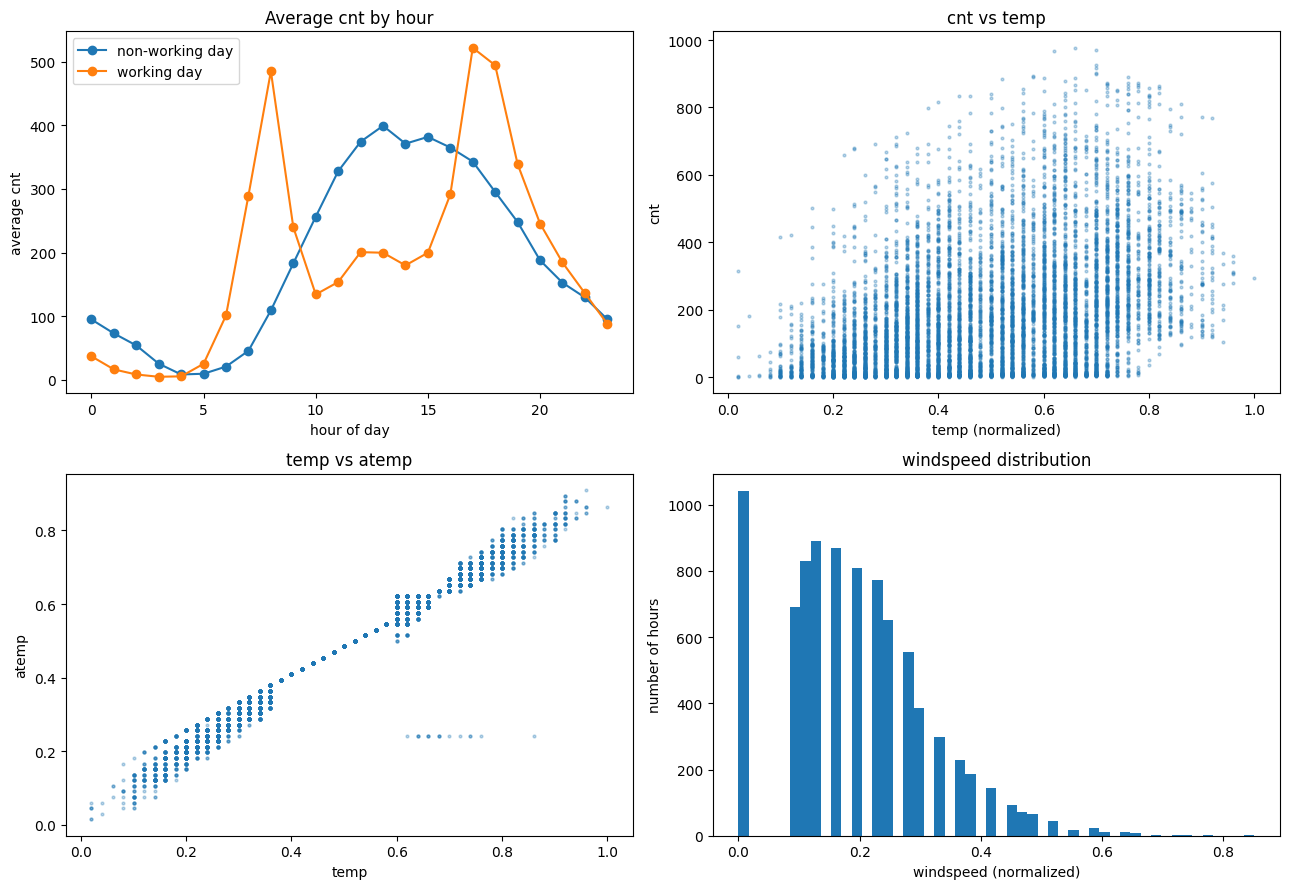

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# 1. average demand by hour, working vs non-working days
hourly = train_df.groupby(["hr", "workingday"])["cnt"].mean().unstack()
hourly.plot(ax=axes[0, 0], marker="o")
axes[0, 0].set(title="Average cnt by hour", xlabel="hour of day", ylabel="average cnt")
axes[0, 0].legend(["non-working day", "working day"])

# 2. demand vs temperature
axes[0, 1].scatter(train_df["temp"], train_df["cnt"], s=4, alpha=0.3)
axes[0, 1].set(title="cnt vs temp", xlabel="temp (normalized)", ylabel="cnt")

# 3. temp vs atemp
axes[1, 0].scatter(train_df["temp"], train_df["atemp"], s=4, alpha=0.3)
axes[1, 0].set(title="temp vs atemp", xlabel="temp", ylabel="atemp")

# 4. windspeed distribution
axes[1, 1].hist(train_df["windspeed"], bins=50)
axes[1, 1].set(title="windspeed distribution", xlabel="windspeed (normalized)", ylabel="number of hours")

plt.tight_layout()
plt.show()

### Analyzing and Finding the bad days


In [ ]:
bad_atemp = train_df[(train_df["temp"] > 0.55) & (train_df["atemp"] < 0.3)]
print("Rows with impossible atemp:", len(bad_atemp))
print("Their dates:", bad_atemp["dteday"].unique())

print("\nDates with hum == 0:", train_df[train_df["hum"] == 0]["dteday"].unique())

Rows with impossible atemp: 16
Their dates: ['2012-08-17']

Dates with hum == 0: ['2011-03-10']


## Feature preparation

In [ ]:
# --- learn the repair rules from TRAINING rows only ---
BAD_ATEMP_DAY = "2012-08-17"

good = train_df[train_df["dteday"] != BAD_ATEMP_DAY]
atemp_slope, atemp_intercept = np.polyfit(good["temp"], good["atemp"], deg=1)
hum_median = train_df.loc[train_df["hum"] > 0, "hum"].median()

print(f"atemp ≈ {atemp_intercept:.4f} + {atemp_slope:.4f} * temp")
print("median humidity (training, zeros excluded):", hum_median)

# --- apply the same rules to any table ---
def fix_quirks(df):
    df = df.copy()
    bad_day = df["dteday"] == BAD_ATEMP_DAY
    df.loc[bad_day, "atemp"] = atemp_intercept + atemp_slope * df.loc[bad_day, "temp"]
    df.loc[df["hum"] == 0, "hum"] = hum_median
    df["weathersit"] = df["weathersit"].replace(4, 3)
    return df

train_fixed = fix_quirks(train_df)
val_fixed   = fix_quirks(val_df)
test_fixed  = fix_quirks(test_X)

# --- checks ---
print("hum == 0 left:", (train_fixed["hum"] == 0).sum(), (val_fixed["hum"] == 0).sum())
print("weathersit values:", sorted(train_fixed["weathersit"].unique()))
print("impossible atemp left:",
      ((train_fixed["temp"] > 0.55) & (train_fixed["atemp"] < 0.3)).sum(),
      ((val_fixed["temp"] > 0.55) & (val_fixed["atemp"] < 0.3)).sum())

atemp ≈ 0.0369 + 0.8861 * temp
median humidity (training, zeros excluded): 0.62
hum == 0 left: 0 0
weathersit values: [np.int64(1), np.int64(2), np.int64(3)]
impossible atemp left: 0 0


In [ ]:
CATEGORIES = {
    "hr":         list(range(24)),
    "season":     [1, 2, 3, 4],
    "mnth":       list(range(1, 13)),
    "weekday":    list(range(7)),
    "weathersit": [1, 2, 3],
}

def one_hot(df):
    parts = []
    for col, cats in CATEGORIES.items():
        dummies = pd.get_dummies(pd.Categorical(df[col], categories=cats),
                                 prefix=col, drop_first=True, dtype=float)
        dummies.index = df.index
        parts.append(dummies)
    return pd.concat(parts, axis=1)

print(one_hot(train_fixed).shape)

(8708, 45)


In [ ]:
CONTINUOUS = ["instant", "temp", "atemp", "hum", "windspeed"]
BINARY     = ["yr", "holiday", "workingday"]

# learn the scaling from TRAINING rows only
mu    = train_fixed[CONTINUOUS].mean()
sigma = train_fixed[CONTINUOUS].std()

def build_features(df_fixed):
    scaled = (df_fixed[CONTINUOUS] - mu) / sigma
    return pd.concat([scaled, df_fixed[BINARY].astype(float), one_hot(df_fixed)], axis=1)

X_train_df = build_features(train_fixed)
X_val_df   = build_features(val_fixed)
X_test_df  = build_features(test_fixed)

feature_names = list(X_train_df.columns)
assert list(X_val_df.columns) == feature_names == list(X_test_df.columns)

def add_bias(X_df):
    return np.c_[np.ones(len(X_df)), X_df.to_numpy()]

X_train, X_val, X_test = add_bias(X_train_df), add_bias(X_val_df), add_bias(X_test_df)
y_train = train_df["cnt"].to_numpy(dtype=float)
y_val   = val_df["cnt"].to_numpy(dtype=float)

# --- checks ---
print("number of features:", len(feature_names))
print("shapes:", X_train.shape, X_val.shape, X_test.shape)
print("any NaN:", np.isnan(X_train).any(), np.isnan(X_val).any(), np.isnan(X_test).any())
print(X_train_df[CONTINUOUS].agg(["mean", "std"]).round(3))

number of features: 53
shapes: (8708, 54) (2178, 54) (574, 54)
any NaN: False False False
      instant  temp  atemp  hum  windspeed
mean     -0.0   0.0    0.0  0.0       -0.0
std       1.0   1.0    1.0  1.0        1.0


In [ ]:
print("columns in X_train:", X_train.shape[1])
print("independent columns (rank):", np.linalg.matrix_rank(X_train))

weekday_cols = [f"weekday_{d}" for d in range(1, 6)]
identity = X_train_df[weekday_cols].sum(axis=1) - X_train_df["holiday"]
print("workingday == weekday_1..5 - holiday ?", np.allclose(identity, X_train_df["workingday"]))

print("seasons per month in train.csv:", train_all.groupby("mnth")["season"].nunique().to_dict())

columns in X_train: 54
independent columns (rank): 50
workingday == weekday_1..5 - holiday ? True
seasons per month in train.csv: {1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1, 8: 1, 9: 1, 10: 1, 11: 1, 12: 1}


# Phase 1: Gradient Descent

### Expectation

In [ ]:
def predict(X, w):
    return X @ w

def mse(X, y, w):
    residuals = predict(X, w) - y
    return np.mean(residuals ** 2)

def mse_gradient(X, y, w):
    n = len(y)
    return (2 / n) * X.T @ (predict(X, w) - y)

def gradient_descent(X, y, lr, max_iters=50_000, tol=1e-7, w_init=None):
    w = np.zeros(X.shape[1]) if w_init is None else w_init.astype(float).copy()
    history = [mse(X, y, w)]
    status = "hit max_iters"

    for it in range(1, max_iters + 1):
        w = w - lr * mse_gradient(X, y, w)
        loss = mse(X, y, w)
        history.append(loss)

        if not np.isfinite(loss) or loss > 1e3 * history[0]:
            status = "diverged"
            break
        if abs(history[-2] - loss) / history[-2] < tol:
            status = "converged"
            break

    return w, np.array(history), status

def r2(y, y_pred):
    return 1 - np.sum((y - y_pred) ** 2) / np.sum((y - np.mean(y)) ** 2)

def rmse(y, y_pred):
    return np.sqrt(np.mean((y - y_pred) ** 2))

In [ ]:
# Check that gradient descent works on the training data

w_test, hist_test, status_test = gradient_descent(X_train, y_train, lr=0.01, max_iters=200)
print("status:", status_test)
print("loss at start:", round(hist_test[0], 1))
print("loss after 200 steps:", round(hist_test[-1], 1))
print("loss always decreasing:", np.all(np.diff(hist_test) <= 0))

status: hit max_iters
loss at start: 69361.0
loss after 200 steps: 19280.4
loss always decreasing: True


In [ ]:
#Predict the maximum safe learning rate

H = (2 / len(y_train)) * X_train.T @ X_train
eigenvalues = np.linalg.eigvalsh(H)
print("largest curvature:", eigenvalues.max())
print("smallest curvature:", eigenvalues.min())
print("predicted max stable learning rate (2 / largest):", 2 / eigenvalues.max())

largest curvature: 4.81661014383946
smallest curvature: 1.3240626361202798e-16
predicted max stable learning rate (2 / largest): 0.41522978615116685


In [ ]:
# Plot the training loss for different learning rates

import time

learning_rates = [0.001, 0.01, 0.1, 0.3, 0.4, 0.45]
runs = {}

for lr in learning_rates:
    start = time.time()
    w, hist, status = gradient_descent(X_train, y_train, lr=lr)
    runs[lr] = (w, hist, status)
    val_r2 = r2(y_val, predict(X_val, w)) if status != "diverged" else float("nan")
    print(f"lr={lr:<6} {status:<14} iterations={len(hist)-1:<6} "
          f"final train MSE={hist[-1]:<14.1f} val R²={val_r2:.4f}  ({time.time()-start:.1f}s)")

lr=0.001  hit max_iters  iterations=50000  final train MSE=10453.9        val R²=0.6790  (60.2s)
lr=0.01   hit max_iters  iterations=50000  final train MSE=9959.7         val R²=0.6929  (64.5s)
lr=0.1    converged      iterations=9241   final train MSE=9937.0         val R²=0.6936  (11.7s)
lr=0.3    converged      iterations=3676   final train MSE=9935.9         val R²=0.6936  (3.6s)
lr=0.4    converged      iterations=2882   final train MSE=9935.8         val R²=0.6936  (2.7s)
lr=0.45   diverged       iterations=25     final train MSE=93749521.5     val R²=nan  (0.0s)


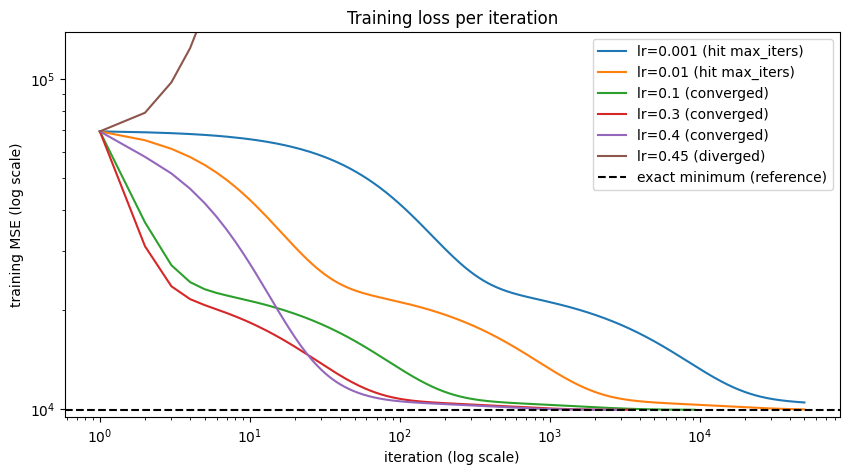

In [ ]:
# Plot the training loss for different learning rates

w_exact = np.linalg.lstsq(X_train, y_train, rcond=None)[0]
best_possible = mse(X_train, y_train, w_exact)

fig, ax = plt.subplots(figsize=(10, 5))
for lr, (w, hist, status) in runs.items():
    ax.plot(np.arange(1, len(hist) + 1), hist, label=f"lr={lr} ({status})")
ax.axhline(best_possible, color="black", linestyle="--", label="exact minimum (reference)")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_ylim(best_possible * 0.95, runs[learning_rates[0]][1][0] * 2)
ax.set(title="Training loss per iteration", xlabel="iteration (log scale)", ylabel="training MSE (log scale)")
ax.legend()
plt.show()

In [ ]:
# Phase 1: One-hot encoding for 'hr'
CHOSEN_LR  = 0.3
CHOSEN_TOL = 1e-7
MAX_ITERS  = 50_000

w_phase1, hist_phase1, status_phase1 = gradient_descent(
    X_train, y_train, lr=CHOSEN_LR, max_iters=MAX_ITERS, tol=CHOSEN_TOL)

train_pred = predict(X_train, w_phase1)
val_pred   = predict(X_val, w_phase1)

print("status:", status_phase1, "| iterations:", len(hist_phase1) - 1)
print(f"train  R² = {r2(y_train, train_pred):.4f}   RMSE = {rmse(y_train, train_pred):.2f}")
print(f"val    R² = {r2(y_val, val_pred):.4f}   RMSE = {rmse(y_val, val_pred):.2f}")
print("gap to exact minimum (train MSE):", round(hist_phase1[-1] - best_possible, 3))
print("negative predictions on validation:", (val_pred < 0).sum(), "of", len(val_pred))

# --- the artifacts Phase 2 must consume ---
phase1 = {
    "weights": w_phase1,
    "learning_rate": CHOSEN_LR,
    "tol": CHOSEN_TOL,
    "iterations": len(hist_phase1) - 1,
    "feature_names": ["bias"] + feature_names,
    "val_r2": r2(y_val, val_pred),
    "val_rmse": rmse(y_val, val_pred),
}

status: converged | iterations: 3676
train  R² = 0.6962   RMSE = 99.68
val    R² = 0.6936   RMSE = 100.89
gap to exact minimum (train MSE): 1.866
negative predictions on validation: 226 of 2178


In [ ]:
# --- Phase 2: treat hr as a single continuous feature instead of one-hot ---
def build_features_hr_raw(df_fixed):
    X = build_features(df_fixed)
    X = X.drop(columns=[c for c in X.columns if c.startswith("hr_")])
    X["hr_raw"] = (df_fixed["hr"] - train_fixed["hr"].mean()) / train_fixed["hr"].std()
    return X

X_train_raw = add_bias(build_features_hr_raw(train_fixed))
X_val_raw   = add_bias(build_features_hr_raw(val_fixed))

w_raw, hist_raw, status_raw = gradient_descent(X_train_raw, y_train, lr=CHOSEN_LR, tol=CHOSEN_TOL)
print("hr as one number:", status_raw,
      f"| val R² = {r2(y_val, predict(X_val_raw, w_raw)):.4f}",
      f"| val RMSE = {rmse(y_val, predict(X_val_raw, w_raw)):.2f}")
print("hr one-hot:      ", f"val R² = {phase1['val_r2']:.4f} | val RMSE = {phase1['val_rmse']:.2f}")

hr as one number: converged | val R² = 0.4070 | val RMSE = 140.36
hr one-hot:       val R² = 0.6936 | val RMSE = 100.89


### Justification

**How we represented each column**
- `hr`: one-hot (23 yes/no columns, midnight as the reference). Demand has two rush-hour peaks on working days (8 AM and 5–6 PM), and a single number can only say "later = more". Evidence: hr as one number gave validation R² 0.4070; one-hot gave 0.6936.
- `season`, `mnth`, `weekday`: one-hot. Their codes are labels, not amounts: "season 4" is not "twice season 2", and December sits next to January.
- `weathersit`: category 4 merged into 3, then one-hot. Category 4 appears in only 1 training row and 0 test rows, so it cannot be learned; both are rain/snow.
- `yr`, `holiday`, `workingday`: kept as 0/1.
- `dteday`: not used as a feature. Year, month, season and weekday are already separate columns. Day of month would be useless for the test set: training has days 1–19, the test is always the 20th.
- `instant`: kept and standardized, so Phase 4 could judge it with evidence.

**Broken readings we fixed**
- `atemp` on 2012-08-17 (16 training rows) showed ~0.24 on hot hours, which is impossible. We recomputed it from temp with the line atemp ≈ 0.0369 + 0.8861 × temp, learned on the other training rows.
- `hum` = 0 on 2011-03-10 (17 rows, a sensor failure; that day also has missing hours): replaced by the training median, 0.62.
- `windspeed` = 0 (1,041 rows, 12%): left as is. The gap between 0 and ~0.09 suggests the sensor reads light wind as 0, and guessing 12% of a column would mean inventing data.

**Scaling**
- Standardized the 5 continuous columns (instant, temp, atemp, hum, windspeed) using the training mean and standard deviation only, then applied the same values to validation and test. Their ranges differed by ~17,000× (instant 1–17,093 vs temp 0–1). The 0/1 columns were left as they are.

**Redundant columns we found**
- The 54 columns contain only 50 independent pieces of information (rank 50). workingday = weekday₁…₅ − holiday exactly, and every month has exactly one season in train.csv. We kept these columns so Phase 4 could judge them, and did not interpret their individual weights.

**Gradient descent settings**
- Learning rate 0.3. The bowl's steepest direction sets a safe limit of 2 / 4.82 = 0.415. Our tests confirmed it: 0.45 exploded in 25 steps; 0.4 worked but sits at 96% of the limit; 0.001 and 0.01 were still far from the bottom after 50,000 steps. 0.3 reached the bottom in 3,676 steps with a safety margin.
- Stopping rule: stop when the loss improves by less than 0.00001% (1e-7) of itself in one step. The final loss was within 1.87 of the exact minimum (about 0.02%), and every working learning rate gave the same validation R², so a stricter rule would change nothing.
- Maximum 50,000 steps, only as a safety net. Starting weights: all zeros.
- Target: raw `cnt`, so errors are measured directly in bikes.

### Outcome

**Results**
- Train: R² 0.6962, RMSE 99.68. Validation: R² 0.6936, RMSE 100.89.
- Always guessing the average would miss by about 181 bikes; our model misses by about 101, roughly 44% better.
- Train and validation scores are almost the same, so the model is not memorizing. Both being stuck around 0.69 points to the formula's straight-line shape as the limit, which is what Phase 2 addresses.

**Expectation vs. result**
- The learning-rate limit held exactly: we calculated 0.415 before testing, 0.4 worked and 0.45 exploded.
- The learning rate changed the speed, not the destination: every working rate ended at the same loss and the same validation R².
- We expected the model to predict some negative rentals at night, and it did: 226 of 2,178 validation hours. 189 of them fall between midnight and 5 AM, when real demand is near zero and the added weather and season effects push the sum below zero. The formula has no floor at zero.
- Describing the hour correctly mattered far more than we expected: one-hot hours raised validation R² from 0.4070 to 0.6936.

**What surprised us**
- How much the way we described a single column mattered. Same data, same algorithm, but switching the hour from one number to 23 yes/no columns raised R² from 0.41 to 0.69.


**Handed to Phase 2**
- Weight vector (54 values including the bias), learning rate 0.3, 3,676 iterations.

In [ ]:
val_df.loc[val_pred < 0, "hr"].value_counts()

,count
hr,
4,41
2,35
3,34
1,31
5,31
0,17
6,13
23,12
22,7


## Bonus: asymmetric loss

### Expectation

Guessing too low would affect x3, so it moves up. the expected missing bikes is about 100 bikes so probably tens of bikes, not hundreds. It won't move all the way up, because guessing too high still costs something (×1)

In [ ]:
UNDER_COST = 3.0

def asym_weights(X, y, w):
    # 3 where we guessed too low, 1 otherwise
    return np.where(y > predict(X, w), UNDER_COST, 1.0)

def asym_loss(X, y, w):
    residuals = predict(X, w) - y
    return np.mean(asym_weights(X, y, w) * residuals ** 2)

def asym_gradient(X, y, w):
    n = len(y)
    c = asym_weights(X, y, w)
    return (2 / n) * X.T @ (c * (predict(X, w) - y))

def gd_general(X, y, lr, loss_fn, grad_fn, max_iters=50_000, tol=1e-7, w_init=None):
    w = np.zeros(X.shape[1]) if w_init is None else w_init.astype(float).copy()
    history = [loss_fn(X, y, w)]
    status = "hit max_iters"
    for it in range(1, max_iters + 1):
        w = w - lr * grad_fn(X, y, w)
        loss = loss_fn(X, y, w)
        history.append(loss)
        if not np.isfinite(loss) or loss > 1e3 * history[0]:
            status = "diverged"
            break
        if abs(history[-2] - loss) / history[-2] < tol:
            status = "converged"
            break
    return w, np.array(history), status

In [ ]:
rng = np.random.default_rng(0)
w_check = w_phase1 + rng.normal(0, 5, len(w_phase1))

formula = asym_gradient(X_train, y_train, w_check)

eps = 1e-4
numeric = np.array([
    (asym_loss(X_train, y_train, w_check + eps * e) - asym_loss(X_train, y_train, w_check - eps * e)) / (2 * eps)
    for e in np.eye(len(w_check))[:6]
])

print("formula :", formula[:6].round(3))
print("measured:", numeric.round(3))
print("largest difference:", np.abs(formula[:6] - numeric).max())

formula : [-125.345   -8.671    6.396    5.715   -2.247    5.889]
measured: [-125.345   -8.671    6.396    5.715   -2.247    5.889]
largest difference: 1.4671059034299105e-08


In [ ]:
# 0.3 was safe for MSE. Is it still safe now?
_, _, status_03 = gd_general(X_train, y_train, 0.3, asym_loss, asym_gradient, w_init=w_phase1)
print("lr 0.3:", status_03)

ASYM_LR = 0.1
w_asym, hist_asym, status_asym = gd_general(
    X_train, y_train, ASYM_LR, asym_loss, asym_gradient, w_init=w_phase1)
print(f"lr {ASYM_LR}: {status_asym} after {len(hist_asym) - 1} iterations")

lr 0.3: diverged
lr 0.1: converged after 2135 iterations


In [ ]:
# --- compare the two models on the validation set ---

pred_mse  = predict(X_val, w_phase1)
pred_asym = predict(X_val, w_asym)

def asym_cost(y, p):
    return np.mean(np.where(y > p, UNDER_COST, 1.0) * (p - y) ** 2)

summary = pd.DataFrame({
    "average prediction":  [pred_mse.mean(), pred_asym.mean()],
    "% hours too low":     [(y_val > pred_mse).mean() * 100, (y_val > pred_asym).mean() * 100],
    "RMSE":                [rmse(y_val, pred_mse), rmse(y_val, pred_asym)],
    "R²":                  [r2(y_val, pred_mse), r2(y_val, pred_asym)],
    "operator's cost":     [asym_cost(y_val, pred_mse), asym_cost(y_val, pred_asym)],
}, index=["MSE model (Phase 1)", "asymmetric model"]).round(2)

print("actual average demand (validation):", round(y_val.mean(), 1))
print(summary)
print("\naverage shift per hour:", round((pred_asym - pred_mse).mean(), 1), "bikes")
print("% of hours shifted up:", round((pred_asym > pred_mse).mean() * 100, 1))

actual average demand (validation): 192.1
                     average prediction  % hours too low    RMSE    R²  \
MSE model (Phase 1)               191.1            46.46  100.89  0.69   
asymmetric model                  232.7            32.83  111.10  0.63   

                     operator's cost  
MSE model (Phase 1)         21656.87  
asymmetric model            17677.93  

average shift per hour: 41.6 bikes
% of hours shifted up: 99.8


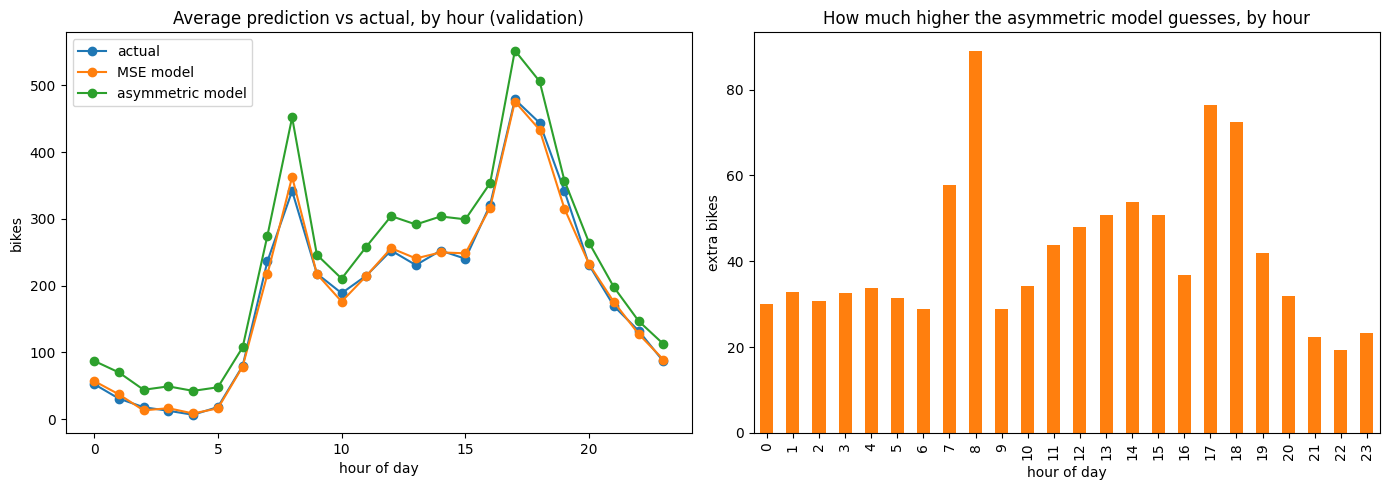

In [ ]:
# --- visualize the difference between the two models ---

by_hour = pd.DataFrame({
    "hr": val_df["hr"].values,
    "actual": y_val,
    "MSE model": pred_mse,
    "asymmetric model": pred_asym,
}).groupby("hr").mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

by_hour.plot(ax=axes[0], marker="o")
axes[0].set(title="Average prediction vs actual, by hour (validation)", xlabel="hour of day", ylabel="bikes")

(by_hour["asymmetric model"] - by_hour["MSE model"]).plot(kind="bar", ax=axes[1], color="tab:orange")
axes[1].set(title="How much higher the asymmetric model guesses, by hour", xlabel="hour of day", ylabel="extra bikes")

plt.tight_layout()
plt.show()

### Outcome

**Expectation vs. result**
- Learning rate: we expected 0.3 to fail because the loss is up to 3× steeper. It diverged; 0.1 converged in 2,135 iterations.
- Direction: we expected predictions to rise. The average prediction rose from 191 to 233 bikes (+42), and 99.8% of hours moved up.
- Old metrics: we expected RMSE and R² to get worse, since the MSE model is the best possible under MSE. RMSE went from 100.9 to 111.1, R² from 0.69 to 0.63.
- Where the shift is largest: we expected rush hours. Confirmed: about +89 bikes at 8 AM and +77 at 5 PM, versus about +20 late in the evening.

**What it means for the operator**
- Hours with too few bikes dropped from 46% to 33%.
- The operator's cost (under-prediction counted 3×) dropped from 21,657 to 17,678, about 18% lower.
- The new model is less accurate by the old rule but cheaper by the operator's rule: it is deliberately wrong in the cheaper direction.

**Derivation check**
- Our derived gradient matched a numerical measurement to about 1e-8.

**Limitation**
- Night hours (2–5 AM) also get about +30 bikes although real demand is about 10–15, because part of the margin comes from shared weights (like the intercept) that apply to every hour.

**What surprised us**
- At 8 AM, real demand averages about 345, and the new model guesses about 450. At 5 PM, about 478 vs. about 550.Real demand is about 10–15 bikes, but the new model guesses about 45–50. That’s roughly 3–4× too many. The right plot shows that even quiet night hours get about 30 extra bikes.

# Phase 2: Polynomial Regression

### Expectation (written before running)
- Phase 1 had two weaknesses: it cannot bend (temperature helps until it gets too hot) and it cannot combine (8 AM is busy on working days but quiet on weekends).
- We add two kinds of polynomial terms: powers of `temp` and `hum` (to bend), and products `hour × workingday` (degree-2 terms, to combine).
- We expect the products to help much more than the powers. The hour pattern is the strongest pattern in the data, and Phase 1 gets it wrong on every weekend hour. The temperature curve only matters in the hottest hours, which are few.
- We expect validation R² to rise with degree at first, then flatten: each extra power adds less new bending.
- We expect the train–validation gap to stay small: even at degree 6 we only add about 33 columns, against 8,708 training rows.
- We expect the safe learning rate to drop as the degree rises, because higher powers make the loss bowl steeper.
- Starting from Phase 1's weights (new weights = 0), the first guesses should be exactly Phase 1's guesses.

In [ ]:
#Checking the input for this phase is the output of phase(1)

POWER_COLS = ["temp", "hum"]
HOUR_COLS  = [f"hr_{h}" for h in range(1, 24)]

def extra_columns(X_df, degree, use_powers=True, use_products=True):
    new = {}
    if use_powers:
        for col in POWER_COLS:
            for p in range(2, degree + 1):
                new[f"{col}^{p}"] = X_df[col] ** p
    if use_products:
        for h in HOUR_COLS:
            new[f"{h}*workingday"] = X_df[h] * X_df["workingday"]
    return pd.DataFrame(new, index=X_df.index)

def build_poly(degree, use_powers=True, use_products=True):
    tr = extra_columns(X_train_df, degree, use_powers, use_products)
    va = extra_columns(X_val_df,   degree, use_powers, use_products)
    te = extra_columns(X_test_df,  degree, use_powers, use_products)

    # rescale the power columns with TRAINING statistics only
    power_cols = [c for c in tr.columns if "^" in c]
    if power_cols:
        m, s = tr[power_cols].mean(), tr[power_cols].std()
        for d in (tr, va, te):
            d[power_cols] = (d[power_cols] - m) / s

    X_tr = np.c_[X_train, tr.to_numpy()]
    X_va = np.c_[X_val,   va.to_numpy()]
    X_te = np.c_[X_test,  te.to_numpy()]
    return X_tr, X_va, X_te, list(tr.columns)

def warm_start(n_new):
    # Phase 1 weights for the old columns, 0 for every new column
    return np.r_[phase1["weights"], np.zeros(n_new)]

def safe_lr(X, margin=0.7):
    H = (2 / len(X)) * X.T @ X
    limit = 2 / np.linalg.eigvalsh(H).max()
    return margin * limit, limit

# --- checks ---
X_tr2, X_va2, _, names2 = build_poly(3)
print("Phase 1 columns:", X_train.shape[1], "| new columns:", len(names2), "| total:", X_tr2.shape[1])
w0 = warm_start(len(names2))
print("same predictions as Phase 1 at the start?",
      np.allclose(predict(X_va2, w0), predict(X_val, phase1["weights"])))

Phase 1 columns: 54 | new columns: 27 | total: 81
same predictions as Phase 1 at the start? True


In [ ]:
#Checking every degree from 1-6

import time

DEGREES = [1, 2, 3, 4, 5, 6]
results, models = [], {}

for d in DEGREES:
    X_tr_d, X_va_d, X_te_d, new_names = build_poly(d)
    lr, limit = safe_lr(X_tr_d)
    start = time.time()
    w, hist, status = gradient_descent(X_tr_d, y_train, lr=lr,
                                       w_init=warm_start(len(new_names)))
    models[d] = (w, X_tr_d, X_va_d, X_te_d, new_names)
    results.append({
        "degree": d, "columns": X_tr_d.shape[1], "lr": round(lr, 3), "status": status,
        "iterations": len(hist) - 1,
        "train R²": r2(y_train, predict(X_tr_d, w)), "val R²": r2(y_val, predict(X_va_d, w)),
        "train RMSE": rmse(y_train, predict(X_tr_d, w)), "val RMSE": rmse(y_val, predict(X_va_d, w)),
    })
    print(f"degree {d} done ({time.time() - start:.0f}s)")

results_df = pd.DataFrame(results).set_index("degree").round(4)
results_df

degree 1 done (17s)
degree 2 done (22s)
degree 3 done (20s)
degree 4 done (25s)
degree 5 done (26s)
degree 6 done (29s)


,columns,lr,status,iterations,train R²,val R²,train RMSE,val RMSE
degree,,,,,,,,
1,77,0.289,converged,9550,0.8333,0.8310,73.8383,74.9300
2,79,0.288,converged,10202,0.8345,0.8337,73.5790,74.3241
3,81,0.229,converged,10960,0.8396,0.8357,72.4209,73.8910
4,83,0.228,converged,11179,0.8412,0.8371,72.0720,73.5581
5,85,0.183,converged,12719,0.8413,0.8373,72.0559,73.5272
6,87,0.174,converged,12972,0.8414,0.8376,72.0118,73.4594


In [ ]:
#Confirming degree=4 is the best decision for the model

rng = np.random.default_rng(0)
val_preds = {d: predict(models[d][2], models[d][0]) for d in DEGREES}

def bootstrap_rmse_gain(d_from, d_to, n_boot=2000):
    err_from = (y_val - val_preds[d_from]) ** 2
    err_to   = (y_val - val_preds[d_to]) ** 2
    n = len(y_val)
    gains = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        gains.append(np.sqrt(err_from[idx].mean()) - np.sqrt(err_to[idx].mean()))
    low, high = np.percentile(gains, [2.5, 97.5])
    real = "real" if low > 0 else "not distinguishable from luck"
    print(f"degree {d_from} → {d_to}: RMSE gain {np.sqrt(err_from.mean()) - np.sqrt(err_to.mean()):.3f} bikes, "
          f"95% range [{low:.3f}, {high:.3f}] → {real}")

for a, b in [(3, 4), (4, 5), (4, 6)]:
    bootstrap_rmse_gain(a, b)

degree 3 → 4: RMSE gain 0.333 bikes, 95% range [0.048, 0.626] → real
degree 4 → 5: RMSE gain 0.031 bikes, 95% range [-0.041, 0.095] → not distinguishable from luck
degree 4 → 6: RMSE gain 0.099 bikes, 95% range [-0.015, 0.214] → not distinguishable from luck


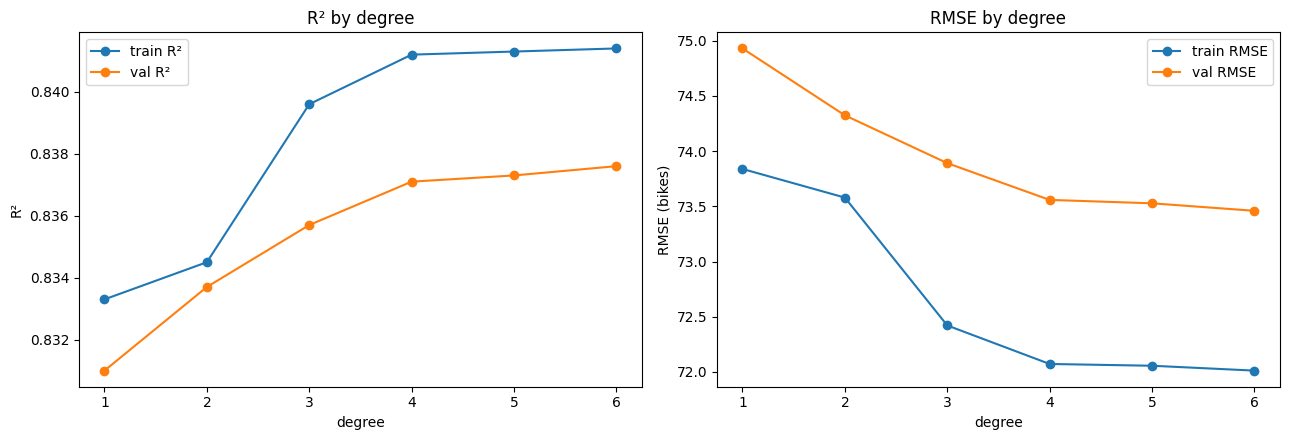

In [ ]:
#Plot the results for R² and RMSE by degree

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
results_df[["train R²", "val R²"]].plot(ax=axes[0], marker="o")
axes[0].set(title="R² by degree", xlabel="degree", ylabel="R²", xticks=DEGREES)
results_df[["train RMSE", "val RMSE"]].plot(ax=axes[1], marker="o")
axes[1].set(title="RMSE by degree", xlabel="degree", ylabel="RMSE (bikes)", xticks=DEGREES)
plt.tight_layout()
plt.show()

In [ ]:
#evidence for “which features are worth expanding.”

D = 4
variants = {
    "Phase 1 (no expansion)": (False, False),
    "powers only":            (True,  False),
    "products only":          (False, True),
    "powers + products":      (True,  True),
}
for name, (pw, pr) in variants.items():
    if not pw and not pr:
        print(f"{name:<24} val R² = {phase1['val_r2']:.4f}")
        continue
    X_tr_v, X_va_v, _, nn = build_poly(D, use_powers=pw, use_products=pr)
    lr, _ = safe_lr(X_tr_v)
    w, hist, status = gradient_descent(X_tr_v, y_train, lr=lr, w_init=warm_start(len(nn)))
    print(f"{name:<24} val R² = {r2(y_val, predict(X_va_v, w)):.4f}   ({status})")

Phase 1 (no expansion)   val R² = 0.6936
powers only              val R² = 0.6991   (converged)
products only            val R² = 0.8310   (converged)
powers + products        val R² = 0.8371   (converged)


In [ ]:
# --- Phase 2: expand the features with powers and products ---
CHOSEN_DEGREE = 4

w_phase2, X_tr_p2, X_va_p2, X_te_p2, names_p2 = models[CHOSEN_DEGREE]
train_pred2 = predict(X_tr_p2, w_phase2)
val_pred2   = predict(X_va_p2, w_phase2)

print(f"train R² = {r2(y_train, train_pred2):.4f}   RMSE = {rmse(y_train, train_pred2):.2f}")
print(f"val   R² = {r2(y_val, val_pred2):.4f}   RMSE = {rmse(y_val, val_pred2):.2f}")
print("negative predictions on validation:", (val_pred2 < 0).sum(), "of", len(val_pred2))

# --- the artifacts Phase 3 must consume ---
phase2 = {
    "degree": CHOSEN_DEGREE,
    "power_columns": POWER_COLS,
    "product_columns": "hr_1..hr_23 × workingday",
    "weights": w_phase2,
    "learning_rate": results_df.loc[CHOSEN_DEGREE, "lr"],
    "iterations": int(results_df.loc[CHOSEN_DEGREE, "iterations"]),
    "train_r2": r2(y_train, train_pred2), "val_r2": r2(y_val, val_pred2),
    "train_rmse": rmse(y_train, train_pred2), "val_rmse": rmse(y_val, val_pred2),
}

train R² = 0.8412   RMSE = 72.07
val   R² = 0.8371   RMSE = 73.56
negative predictions on validation: 258 of 2178


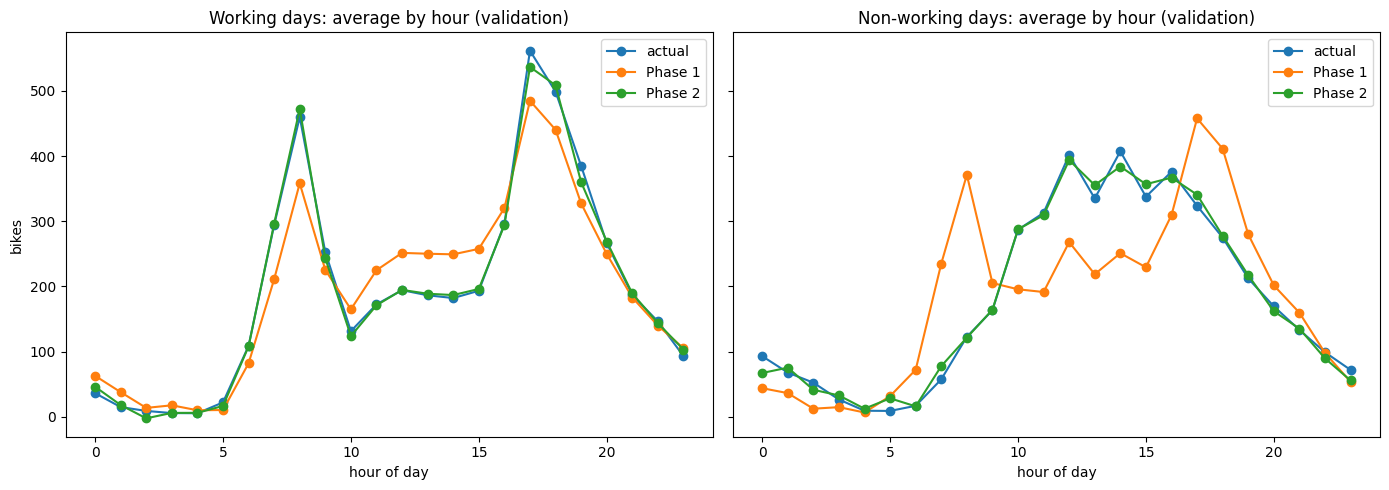

In [ ]:
#--- visualize the difference between the two models ---
by_hour = pd.DataFrame({
    "hr": val_df["hr"].values,
    "workingday": val_df["workingday"].values,
    "actual": y_val,
    "Phase 1": predict(X_val, phase1["weights"]),
    "Phase 2": val_pred2,
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (wd, title) in zip(axes, [(1, "Working days"), (0, "Non-working days")]):
    (by_hour[by_hour["workingday"] == wd]
        .groupby("hr")[["actual", "Phase 1", "Phase 2"]].mean()
        .plot(ax=ax, marker="o"))
    ax.set(title=f"{title}: average by hour (validation)", xlabel="hour of day", ylabel="bikes")
plt.tight_layout()
plt.show()

### Outcome

**Degree**
- Tried degrees 1–6 (degree = highest power of temp and hum; the products are included at every degree).
- Degree 6 has the highest validation R² (0.8376 vs. 0.8371 at degree 4), but the difference is 0.10 bikes of RMSE.
- Bootstrap check on the validation set (2,000 resamples): degree 3 → 4 gains 0.33 bikes, 95% range [0.05, 0.63], so the gain is real. Degree 4 → 6 gains 0.10 bikes, 95% range [−0.02, 0.21], which includes 0, so it cannot be told apart from noise.
- We chose degree 4: the simplest degree whose improvement is real. Higher degrees add columns, need a smaller learning rate (0.174 vs. 0.228), and take more iterations, with no reliable gain.

**Results (degree 4)**
- Train R² 0.8412, RMSE 72.07. Validation R² 0.8371, RMSE 73.56.
- Compared with Phase 1 (validation R² 0.6936, RMSE 100.89): the typical error dropped by about 27 bikes, and the share of variation explained rose from 69% to 84%.


**Expectation vs. result**
- Products vs. powers: confirmed. Products alone raised validation R² from 0.6936 to 0.8310; powers alone only to 0.6991.
- Degree: confirmed it flattens. Degree 1 → 4 adds 0.006 validation R²; degree 4 → 6 adds only 0.0005.
- Train–validation gap: confirmed small at every degree (0.0023 to 0.0041 in R²).
- Learning rate: confirmed it drops with degree (0.289 → 0.174), and all runs converged.
- Warm start: confirmed. The first predictions equal Phase 1's exactly.

**What the hour plot shows**
- Weekend 8 AM: actual 123, Phase 1 371, Phase 2 121. Phase 1 applied the working-day rush hour to weekends; the products fixed that.
- Weekend 1 PM: actual 335, Phase 1 219, Phase 2 355. The weekend midday hump is now captured.

**Limitation**
- Negative predictions on validation: 258 of 2,178 (Phase 1: 226). The formula still has no floor at zero.

**What surprised us**
- The products did almost all the work. Products alone raised validation R² from 0.6936 to 0.8310, while powers alone only reached 0.6991. We expected temperature's curve to matter more, since it was clearly visible in our plot. The likely reason: the curve only changes predictions in the hottest hours, which are few, while the hour-by-day pattern affects every single hour.

**Handed to Phase 3**
- Degree 4 with powers of temp and hum plus hour × workingday products; train R² 0.8412 / validation R² 0.8371 (RMSE 72.07 / 73.56).

# Phase 3: Bias-Variance Tradeoff

### Expectation (written before running)
- In Phase 2, train and validation scores were almost equal, so we expect **no overfitting**: the train–validation gap should stay small at every degree, even at degree 8.
- Validation error stopped improving after degree 4 in Phase 2. We expect higher degrees to change almost nothing, so the remaining error is probably **bias** (what our formula cannot express) or unpredictable noise, not variance.
- Learning curve: with very little data, we expect a low training error and a high validation error. With more data, we expect the two to meet with a small gap, meaning more data would not help much.
- Chronological split: we expect it to be **worse** than the seeded split, because (1) validation hours no longer share days with training hours, and (2) the most recent months may differ from the earlier ones (the system was growing in popularity).
- We expect the chronological drop to appear at **every** degree, so it would be caused by time, not by complexity.

degree 7 done
degree 8 done
        columns  train RMSE  val RMSE  gap (val − train RMSE)  train R²  \
degree                                                                    
1            77     73.8383   74.9300                  1.0917    0.8333   
2            79     73.5790   74.3241                  0.7451    0.8345   
3            81     72.4209   73.8910                  1.4701    0.8396   
4            83     72.0720   73.5581                  1.4861    0.8412   
5            85     72.0559   73.5272                  1.4713    0.8413   
6            87     72.0118   73.4594                  1.4477    0.8414   
7            89     71.9984   73.3619                  1.3635    0.8415   
8            91     71.9968   73.3561                  1.3593    0.8415   

        val R²  
degree          
1       0.8310  
2       0.8337  
3       0.8357  
4       0.8371  
5       0.8373  
6       0.8376  
7       0.8380  
8       0.8380  


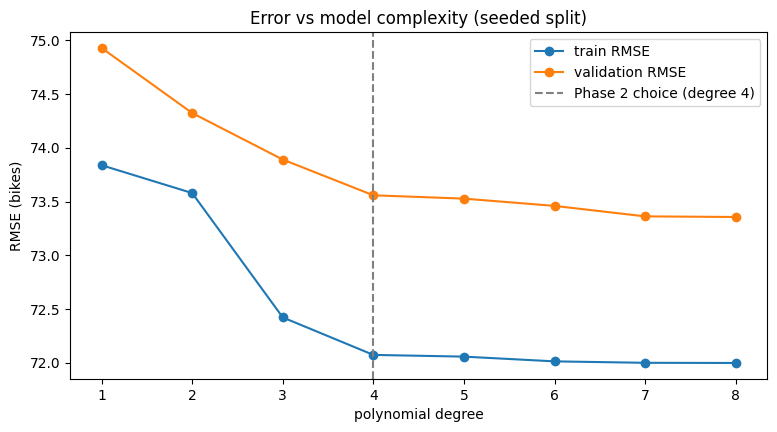

In [ ]:
# degrees 1–6 were trained in Phase 2; add 7 and 8 to see further
for d in [7, 8]:
    X_tr_d, X_va_d, X_te_d, new_names = build_poly(d)
    lr, limit = safe_lr(X_tr_d)
    w, hist, status = gradient_descent(X_tr_d, y_train, lr=lr, w_init=warm_start(len(new_names)))
    models[d] = (w, X_tr_d, X_va_d, X_te_d, new_names)
    results.append({"degree": d, "columns": X_tr_d.shape[1], "lr": round(lr, 3), "status": status,
                    "iterations": len(hist) - 1,
                    "train R²": r2(y_train, predict(X_tr_d, w)), "val R²": r2(y_val, predict(X_va_d, w)),
                    "train RMSE": rmse(y_train, predict(X_tr_d, w)), "val RMSE": rmse(y_val, predict(X_va_d, w))})
    print(f"degree {d} done")

sweep = pd.DataFrame(results).set_index("degree").sort_index()
sweep["gap (val − train RMSE)"] = sweep["val RMSE"] - sweep["train RMSE"]
print(sweep[["columns", "train RMSE", "val RMSE", "gap (val − train RMSE)", "train R²", "val R²"]].round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(sweep.index, sweep["train RMSE"], marker="o", label="train RMSE")
ax.plot(sweep.index, sweep["val RMSE"], marker="o", label="validation RMSE")
ax.axvline(phase2["degree"], color="gray", linestyle="--", label=f"Phase 2 choice (degree {phase2['degree']})")
ax.set(title="Error vs model complexity (seeded split)", xlabel="polynomial degree",
       ylabel="RMSE (bikes)", xticks=list(sweep.index))
ax.legend()
plt.show()

                  status  train RMSE  val RMSE
training rows                                 
435            converged       67.40     79.58
870            converged       68.82     75.96
1741           converged       69.45     74.08
3483           converged       71.32     73.72
5224           converged       71.54     73.63
6966           converged       71.67     73.51
8708           converged       72.07     73.51


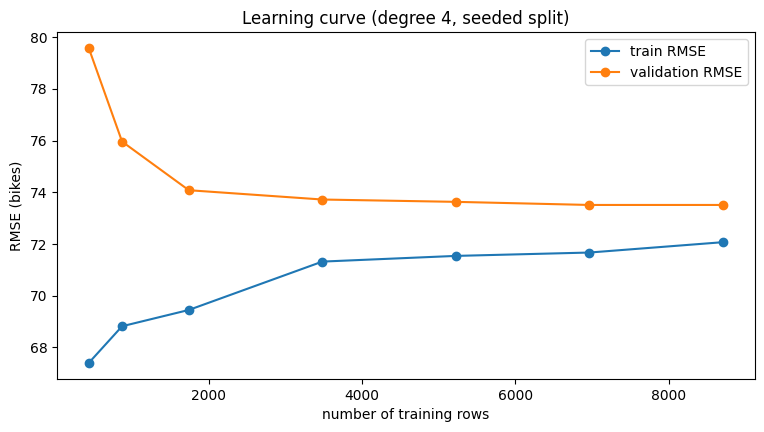

In [ ]:
X_tr_lc, X_va_lc = models[phase2["degree"]][1], models[phase2["degree"]][2]

rng_lc = np.random.default_rng(seed)
order = rng_lc.permutation(len(y_train))
FRACTIONS = [0.05, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0]

curve = []
for frac in FRACTIONS:
    idx = order[: int(frac * len(y_train))]
    lr, _ = safe_lr(X_tr_lc[idx])
    w, hist, status = gradient_descent(X_tr_lc[idx], y_train[idx], lr=lr)
    curve.append({"training rows": len(idx), "status": status,
                  "train RMSE": rmse(y_train[idx], predict(X_tr_lc[idx], w)),
                  "val RMSE":   rmse(y_val, predict(X_va_lc, w))})

curve_df = pd.DataFrame(curve).set_index("training rows").round(2)
print(curve_df)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(curve_df.index, curve_df["train RMSE"], marker="o", label="train RMSE")
ax.plot(curve_df.index, curve_df["val RMSE"], marker="o", label="validation RMSE")
ax.set(title=f"Learning curve (degree {phase2['degree']}, seeded split)",
       xlabel="number of training rows", ylabel="RMSE (bikes)")
ax.legend()
plt.show()

In [ ]:
def fit_pipeline(train_part, other_parts, degree):
    """Learn every transform on train_part only, then apply it to other_parts."""
    # 1. repair rules, learned on train_part
    good = train_part[train_part["dteday"] != BAD_ATEMP_DAY]
    slope, intercept = np.polyfit(good["temp"], good["atemp"], deg=1)
    hum_med = train_part.loc[train_part["hum"] > 0, "hum"].median()

    def fix(df):
        df = df.copy()
        bad_day = df["dteday"] == BAD_ATEMP_DAY
        df.loc[bad_day, "atemp"] = intercept + slope * df.loc[bad_day, "temp"]
        df.loc[df["hum"] == 0, "hum"] = hum_med
        df["weathersit"] = df["weathersit"].replace(4, 3)
        return df

    tr = fix(train_part)
    others = [fix(o) for o in other_parts]

    # 2. scaling, learned on train_part
    mu_c, sigma_c = tr[CONTINUOUS].mean(), tr[CONTINUOUS].std()
    def base(df):
        return pd.concat([(df[CONTINUOUS] - mu_c) / sigma_c, df[BINARY].astype(float), one_hot(df)], axis=1)

    b_tr = base(tr)
    b_others = [base(o) for o in others]

    # 3. same polynomial expansion as Phase 2, power columns rescaled on train_part
    e_tr = extra_columns(b_tr, degree)
    e_others = [extra_columns(b, degree) for b in b_others]
    power_cols = [c for c in e_tr.columns if "^" in c]
    if power_cols:
        pm, ps = e_tr[power_cols].mean(), e_tr[power_cols].std()
        for e in [e_tr] + e_others:
            e[power_cols] = (e[power_cols] - pm) / ps

    def to_X(b, e):
        return np.c_[np.ones(len(b)), b.to_numpy(), e.to_numpy()]
    return to_X(b_tr, e_tr), [to_X(b, e) for b, e in zip(b_others, e_others)]


CUT = "2012-08-01"
chrono_train = train_all[train_all["dteday"] < CUT]
chrono_val   = train_all[train_all["dteday"] >= CUT]
y_ctr = chrono_train["cnt"].to_numpy(dtype=float)
y_cva = chrono_val["cnt"].to_numpy(dtype=float)

print("chronological train:", len(chrono_train), "rows,", chrono_train["dteday"].min(), "to", chrono_train["dteday"].max())
print("chronological val:  ", len(chrono_val), "rows,", chrono_val["dteday"].min(), "to", chrono_val["dteday"].max(),
      f"({len(chrono_val) / len(train_all):.0%} of train.csv)")
print("average cnt: chronological train", round(y_ctr.mean(), 1), "| chronological val", round(y_cva.mean(), 1))

chrono = []
for d in sweep.index:
    X_ctr, (X_cva,) = fit_pipeline(chrono_train, [chrono_val], d)
    lr, _ = safe_lr(X_ctr)
    w, hist, status = gradient_descent(X_ctr, y_ctr, lr=lr)
    p_tr, p_va = predict(X_ctr, w), predict(X_cva, w)
    chrono.append({"degree": d, "status": status,
                   "train RMSE": rmse(y_ctr, p_tr), "val RMSE": rmse(y_cva, p_va),
                   "train R²": r2(y_ctr, p_tr), "val R²": r2(y_cva, p_va),
                   "average error": (p_va - y_cva).mean()})
    print(f"degree {d} done")

chrono_df = pd.DataFrame(chrono).set_index("degree").round(4)
print(chrono_df)

chronological train: 8607 rows, 2011-01-01 to 2012-07-19
chronological val:   2279 rows, 2012-08-01 to 2012-12-19 (21% of train.csv)
average cnt: chronological train 173.0 | chronological val 261.6
degree 1 done
degree 2 done
degree 3 done
degree 4 done
degree 5 done
degree 6 done
degree 7 done


In [ ]:
D = phase2["degree"]

compare = pd.DataFrame({
    "seeded split":        [sweep.loc[D, "train R²"], sweep.loc[D, "val R²"], sweep.loc[D, "val RMSE"]],
    "chronological split": [chrono_df.loc[D, "train R²"], chrono_df.loc[D, "val R²"], chrono_df.loc[D, "val RMSE"]],
}, index=["train R²", "val R²", "val RMSE"]).round(4)
print(compare)

# is the late period simply harder, or is "unseen time" the problem?
late = (val_df["dteday"] >= CUT).to_numpy()
p_seeded = predict(models[D][2], models[D][0])
print(f"\nseeded-split model, its own validation rows BEFORE {CUT}: {(~late).sum()} rows, "
      f"RMSE {rmse(y_val[~late], p_seeded[~late]):.2f}, R² {r2(y_val[~late], p_seeded[~late]):.4f}")
print(f"seeded-split model, its own validation rows FROM {CUT}:  {late.sum()} rows, "
      f"RMSE {rmse(y_val[late], p_seeded[late]):.2f}, R² {r2(y_val[late], p_seeded[late]):.4f}")
print(f"chronological model, all hours FROM {CUT}:             {len(y_cva)} rows, "
      f"RMSE {chrono_df.loc[D, 'val RMSE']:.2f}, R² {chrono_df.loc[D, 'val R²']:.4f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(sweep.index, sweep["val RMSE"], marker="o", label="seeded split: validation")
ax.plot(chrono_df.index, chrono_df["val RMSE"], marker="o", label="chronological split: validation")
ax.plot(chrono_df.index, chrono_df["train RMSE"], marker="o", linestyle="--", label="chronological split: train")
ax.set(title="Seeded vs chronological validation", xlabel="polynomial degree",
       ylabel="RMSE (bikes)", xticks=list(sweep.index))
ax.legend()
plt.show()

In [ ]:
#What phase(4) will consume from phase(3)
phase3 = {
    "diagnosis": "reasonably fit and bias-limited: no overfitting at any degree; "
                 "the seeded-split score is optimistic for unseen time periods",
    "target_degree": phase2["degree"],
    "features": "Phase 2 expansion: powers of temp and hum + hr × workingday products",
    "seeded_val_r2": sweep.loc[phase2["degree"], "val R²"],
    "chrono_val_r2": chrono_df.loc[phase2["degree"], "val R²"],
}
phase3

### Justification

**What we varied**
- Complexity: polynomial degree 1–8, anchored on Phase 2's degree 4 (same features: powers of temp and hum + hr × workingday products).
- Training-set size at degree 4 (5%–100% of the training rows): a learning curve, the second, independent tool for separating bias from variance.

**What we measured**
- Train RMSE, validation RMSE, and their gap (plus R²). A gap that grows with complexity would mean variance (overfitting); errors that stay high with a small gap mean bias.

**Chronological split**
- Cut at 2012-08-01: train on 2011-01-01 – 2012-07-19 (8,607 rows), validate on 2012-08-01 – 2012-12-19 (2,279 rows, 21%), close to the seeded 20% so the two estimates are comparable.
- Every transform (repair rules, scaling, polynomial rescaling) was re-learned on the early dates only, so no information from the later period leaks into training.
- Evaluation models start from zero weights, so each one learns only from its own training data. Phase 3 consumes Phase 2's degree and feature choice.

**Why this evidence distinguishes bias from variance**
- Complexity sweep: variance would show as a gap growing with degree. Learning curve: variance would show as a large gap that shrinks with more data; bias shows as curves meeting at a high error.

### Outcome

**Diagnosis: reasonably fit and bias-limited, not overfit.**
- Complexity sweep: the train–validation gap stays between 0.75 and 1.49 bikes at every degree (1–8) and does not grow. Validation RMSE barely improves after degree 4 (73.56 → 73.36 at degree 8).
- Learning curve: with 435 rows, train RMSE 67.40 vs validation 79.58 (memorizing a small sample). With all 8,708 rows they meet at 72.07 vs 73.51 (gap 1.4). From 60% to 100% of the data, validation improves by only 0.1 bike, so more data would not help.
- Conclusion: the remaining error comes from the model's form (effects are added, not combined beyond what we built) and from unpredictable noise, not from variance.
- Target carried to Phase 4: degree 4 with the same features. Higher degrees gave no reliable improvement.

**The time question**
- Seeded split: validation R² 0.8371, RMSE 73.56. Chronological split: validation R² 0.8018, RMSE 97.02.
- Explaining the gap: (1) the late period is busier (average 262 vs 173 bikes), and even the seeded model's error on its own late-period validation hours is 89.02 (vs 68.57 earlier). (2) Unseen time adds about 8 more bikes (89.02 → 97.02 on the same period): the chronological model has no same-day neighbours and never saw those months. It also under-predicts on average (−5.0 bikes), because demand kept growing after the cut.
- Which estimate to trust: for new data that arrives as unseen time periods, the chronological estimate is the honest one. The seeded estimate is optimistic because validation hours share days with training hours. test.csv (whole unseen days inside the same two years) likely sits between the two.
- Does it change the diagnosis? No. The chronological gap appears at every degree, even degree 1, and is about the same size at each, so it is caused by time (the system's growth and new days), not by complexity.

**What surprised us**
- The chronological RMSE jumped by 23 bikes, but most of that (about 20) was because the late months are simply busier, not because the model fails on new days.

# Phase 4: Regularization (L1, L2, Elastic Net)

### Expectation (written before running)
- Phase 3 found no overfitting (train–validation gap ~1.5 bikes, flat learning curve). Regularization fixes overfitting, so we expect it **not** to improve validation accuracy. The best λ should be small, and large λ should only make things worse.
- Ridge should keep every feature non-zero; Lasso should set some exactly to 0.
- We expect Lasso to zero one member of each redundant pair we found earlier: temp/atemp (almost the same column), season/mnth (each month has exactly one season in train.csv), and the workingday/weekday/holiday group.
- Column verdicts we expect: hr, workingday, temp useful; atemp, season, holiday redundant; windspeed possibly uninformative; dteday redundant (its parts are already separate columns).

In [ ]:
#Prepare for Phase 4: Ridge, Lasso, ElasticNet
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler
warnings.filterwarnings("ignore", category=ConvergenceWarning)

D4 = phase3["target_degree"]                       # consume Phase 3's target
_, X_tr_d, X_va_d, X_te_d, new_names_d = models[D4]
p4_names = feature_names + new_names_d             # 82 feature names (no bias column)

# standardize EVERY feature, learned on training rows only
scaler_p4 = StandardScaler().fit(X_tr_d[:, 1:])
Z_train = scaler_p4.transform(X_tr_d[:, 1:])
Z_val   = scaler_p4.transform(X_va_d[:, 1:])
Z_test  = scaler_p4.transform(X_te_d[:, 1:])
print("features:", Z_train.shape[1], "| shapes:", Z_train.shape, Z_val.shape, Z_test.shape)

In [ ]:
LAMBDAS = np.logspace(1, -3, 17)   # 10 → 0.001, from strongest to weakest penalty

def reg_path(method, l1_ratio=None):
    n = len(y_train)
    if method == "lasso":
        model = Lasso(max_iter=100_000, warm_start=True)
    elif method == "elastic net":
        model = ElasticNet(l1_ratio=l1_ratio, max_iter=100_000, warm_start=True)

    rows, coefs = [], {}
    for lam in LAMBDAS:
        if method == "ridge":
            model = Ridge(alpha=lam * n)   # same λ meaning as Lasso / Elastic Net
        else:
            model.set_params(alpha=lam)
        model.fit(Z_train, y_train)
        p_tr, p_va = model.predict(Z_train), model.predict(Z_val)
        coefs[lam] = model.coef_.copy()
        rows.append({"lambda": lam, "train RMSE": rmse(y_train, p_tr), "val RMSE": rmse(y_val, p_va),
                     "val R²": r2(y_val, p_va), "non-zero": int((np.abs(model.coef_) > 1e-8).sum())})
    return pd.DataFrame(rows), coefs

CONFIGS = {"ridge": ("ridge", None), "lasso": ("lasso", None),
           "elastic net 0.2": ("elastic net", 0.2),
           "elastic net 0.5": ("elastic net", 0.5),
           "elastic net 0.8": ("elastic net", 0.8)}

paths = {}
for label, (method, ratio) in CONFIGS.items():
    paths[label] = reg_path(method, ratio)
    print(f"{label} done")

In [ ]:
TOL = 0.3   # bikes: the noise level from Phase 2's bootstrap

chosen = {}
for label, (df, coefs) in paths.items():
    best = df["val RMSE"].min()
    lam = df.loc[df["val RMSE"] <= best + TOL, "lambda"].max()   # strongest λ that costs ≤ 0.3 bikes
    row = df[df["lambda"] == lam].iloc[0]
    chosen[label] = {"lambda": lam, "best val RMSE": best, "val RMSE": row["val RMSE"],
                     "val R²": row["val R²"], "non-zero": row["non-zero"], "coef": coefs[lam]}

summary = pd.DataFrame(chosen).T.drop(columns="coef").astype(float)
print(f"no regularization (Phase 2, degree {D4}): val RMSE {sweep.loc[D4, 'val RMSE']:.4f}")
print(summary.round(4))

en_labels = [k for k in chosen if k.startswith("elastic")]
best_en = min(en_labels, key=lambda k: chosen[k]["val RMSE"])
print("chosen elastic net:", best_en)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for label, (df, _) in paths.items():
    axes[0].plot(df["lambda"], df["val RMSE"], marker=".", label=label)
    axes[1].plot(df["lambda"], df["non-zero"], marker=".", label=label)
for label, c in chosen.items():
    axes[0].scatter(c["lambda"], c["val RMSE"], s=80, zorder=5, edgecolor="black")
axes[0].set(xscale="log", ylim=(70, 100), title="Validation RMSE vs λ (dots = chosen λ)",
            xlabel="λ (log scale)", ylabel="val RMSE (bikes)")
axes[1].set(xscale="log", title="Number of non-zero weights vs λ",
            xlabel="λ (log scale)", ylabel="non-zero weights")
axes[0].legend()
plt.tight_layout()
plt.show()

In [ ]:
#The features Lasso keeps (handed to Phase 5)
lasso_coef = chosen["lasso"]["coef"]
zeroed    = [nm for nm, c in zip(p4_names, lasso_coef) if abs(c) <= 1e-8]
surviving = [nm for nm, c in zip(p4_names, lasso_coef) if abs(c) > 1e-8]
print(f"Lasso keeps {len(surviving)} of {len(p4_names)} features. Set to zero:")
print(zeroed)

In [ ]:
# which model features come from each ORIGINAL column
COLUMN_FEATURES = {
    "instant":    ["instant"],
    "season":     ["season_2", "season_3", "season_4"],
    "yr":         ["yr"],
    "mnth":       [f"mnth_{m}" for m in range(2, 13)],
    "hr":         [f"hr_{h}" for h in range(1, 24)] + [f"hr_{h}*workingday" for h in range(1, 24)],
    "holiday":    ["holiday"],
    "weekday":    [f"weekday_{d}" for d in range(1, 7)],
    "workingday": ["workingday"] + [f"hr_{h}*workingday" for h in range(1, 24)],
    "weathersit": ["weathersit_2", "weathersit_3"],
    "temp":       ["temp", "temp^2", "temp^3", "temp^4"],
    "atemp":      ["atemp"],
    "hum":        ["hum", "hum^2", "hum^3", "hum^4"],
    "windspeed":  ["windspeed"],
}

ridge_lam = chosen["ridge"]["lambda"]

def val_rmse_without(drop):
    keep = [i for i, nm in enumerate(p4_names) if nm not in set(drop)]
    m = Ridge(alpha=ridge_lam * len(y_train)).fit(Z_train[:, keep], y_train)
    return rmse(y_val, m.predict(Z_val[:, keep]))

base_rmse = val_rmse_without([])

# 1. remove each column on its own
rows = []
for col, feats in COLUMN_FEATURES.items():
    n_zero = sum(f in zeroed for f in feats)
    rows.append({"column": col,
                 "RMSE increase when removed": val_rmse_without(feats) - base_rmse,
                 "Lasso zeros": f"{n_zero} of {len(feats)}"})
drop_table = (pd.DataFrame(rows).set_index("column")
              .sort_values("RMSE increase when removed", ascending=False))
print(f"baseline val RMSE (Ridge, λ={ridge_lam:.4g}, all features): {base_rmse:.2f}")
print(drop_table.round(3))

# 2. remove suspected redundant PAIRS together
PAIRS = [("temp", "atemp"), ("instant", "yr"), ("season", "mnth"), ("weekday", "holiday")]
print()
for a, b in PAIRS:
    both = val_rmse_without(COLUMN_FEATURES[a] + COLUMN_FEATURES[b]) - base_rmse
    print(f"remove {a} AND {b} together: +{both:.3f} bikes")
print("remove workingday's own column only (keep hr × workingday products):",
      f"+{val_rmse_without(['workingday']) - base_rmse:.3f} bikes")

# 3. exact relationships in the raw data
print("\ndates with more than one value (0 = fully determined by dteday):")
print({c: int((train_all.groupby("dteday")[c].nunique() > 1).sum())
       for c in ["season", "yr", "mnth", "holiday", "weekday", "workingday"]})
print("correlation temp–atemp:", round(np.corrcoef(X_train_df["temp"], X_train_df["atemp"])[0, 1], 3),
      "| instant–yr:", round(np.corrcoef(X_train_df["instant"], X_train_df["yr"])[0, 1], 3))

In [ ]:
#--- Phase 4 artifacts for Phase 5 ---
phase4 = {
    "degree": D4,
    "lambda": {label: chosen[label]["lambda"] for label in ["ridge", "lasso", best_en]},
    "elastic_net_l1_ratio": float(best_en.split()[-1]),
    "surviving_features": surviving,            # Lasso non-zero features → Phase 5
    "val_rmse": {label: chosen[label]["val RMSE"] for label in ["ridge", "lasso", best_en]},
}
print(phase4["lambda"], "| l1_ratio:", phase4["elastic_net_l1_ratio"],
      "| surviving features:", len(phase4["surviving_features"]))

### Justification

**Tool and features**
- scikit-learn's Ridge, Lasso and ElasticNet (the PDF restricts sklearn only in Phases 1–2). Lasso's exact zeros need a coordinate-descent solver.
- Features: Phase 3's target, degree 4 (82 features: Phase 1 features + powers of temp and hum + hr × workingday products).

**Scaling**
- Every feature standardized (including 0/1 switches), fitted on training rows only. The penalty treats all weights equally, so features must be on the same scale for the penalty to be fair. The intercept is not penalized.

**λ search (informed by Phase 3)**
- Phase 3 found no overfitting, so we did not expect regularization to improve accuracy; we searched for the strongest penalty that costs nothing.
- Grid: 17 values of λ from 10 to 0.001 (log-spaced), searched from strongest to weakest with warm starts. Elastic Net l1_ratio ∈ {0.2, 0.5, 0.8}.
- Rule: for each method, the largest λ whose validation RMSE is within 0.3 bikes of that method's best. 0.3 bikes is the noise level measured by the Phase 2 bootstrap; within it, differences are not real, so we prefer the simpler model.

**Fair comparison**
- Same features, scaling, split, λ grid and selection rule for all three methods. Ridge uses alpha = λ·n, which makes λ the same penalty strength as in Lasso and Elastic Net (Ridge = Elastic Net with l1_ratio = 0).

**Column verdicts**
- Each original column: remove all model features built from it, refit Ridge at its chosen λ, and measure the increase in validation RMSE. Suspected redundant pairs are also removed together. An increase above 0.3 bikes (the noise level) counts as a real contribution.
- Supported by Lasso zeros and by exact relationships in the raw data (dteday determines six columns; workingday = weekday₁…₅ − holiday).

### Outcome

**Expectation vs. result**
- Accuracy: confirmed no gain. Best validation RMSE was 73.48 (Lasso) vs 73.56 without regularization, a 0.08-bike difference, below the 0.3-bike noise level. This confirms Phase 3: there was no overfitting to cure.
- Chosen λ: Ridge 0.01 (val RMSE 73.74), Lasso 0.316 (73.77, 74 of 82 features non-zero), Elastic Net l1_ratio 0.8 with λ 0.0316 (73.65, 80 non-zero). All three are within 0.12 bikes of each other.
- Ridge kept all 82 features, as expected. Lasso zeroed 8: yr, hr_23, season_3, mnth_6, mnth_12, weekday_3, hum², hum⁴.
- Partly wrong: we expected Lasso to remove atemp, but it removed yr instead. Removing temp and atemp together costs 3.25 bikes, and atemp alone 0.33, so Lasso keeps a little of atemp. Removing instant and yr together costs 11.43 bikes while each alone costs ~0, so one had to stay; Lasso kept instant.

**Column verdicts**
- Useful: hr (+72.24 bikes when removed), workingday (+26.42, through the hr × workingday products), temp (+1.20), mnth (+0.95), hum (+0.90), weathersit (+0.76).
- Redundant: atemp (with temp; correlation 0.992), instant and yr (with each other), season (with mnth), holiday and weekday (with workingday), dteday (determines six other columns exactly).
- Uninformative: windspeed (+0.16, below noise, no other column carries wind).

**What surprised us**
- Removing the workingday column alone costs almost nothing (0.04), but removing it together with its hour products costs 26 bikes. Its value comes entirely from being combined with the hour.

**Handed to Phase 5**
- λ per method (Ridge 0.01, Lasso 0.316, Elastic Net 0.0316 with l1_ratio 0.8) and the 74 features Lasso leaves non-zero.

# Phase 5: Logistic Regression

### Expectation (written before running)
- With a single global threshold, we expect night hours to almost never be "high" and rush hours to almost always be, so the hour alone would predict the label well. That label would be trivially easy and not useful to the operator.
- With a threshold per hour × day type × year group, every hour of the day should have roughly the same share of "high" (about 25%), and the hour alone should predict almost nothing.
- The relative label is harder, so we expect a lower ROC-AUC than the global label would give, but well above 0.5, because weather and season still explain why some hours are busier than usual for their slot.
- Since only ~25% of hours are "high", always answering "not high" would reach ~75% accuracy, so we expect accuracy to be misleading and will judge by F1 and ROC-AUC.
- We expect a cutoff below 0.5 to give a better F1, because with few positives the model rarely reaches 0.5 probability.

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, roc_curve, confusion_matrix

tr5 = train_df.reset_index(drop=True)
va5 = val_df.reset_index(drop=True)

GLOBAL_THR = np.percentile(y_train, 75)
y_tr_global = (y_train > GLOBAL_THR).astype(int)
y_va_global = (y_val > GLOBAL_THR).astype(int)

share_global = pd.Series(y_tr_global).groupby(tr5["hr"]).mean()
print(f"global threshold: cnt > {GLOBAL_THR:.0f} bikes → {y_tr_global.mean():.1%} of training hours are 'high'")
print("hours that are NEVER high:", list(share_global[share_global == 0].index))
print("guess using ONLY the hour → validation ROC-AUC:",
      round(roc_auc_score(y_va_global, va5["hr"].map(share_global)), 3))

In [ ]:
GROUP = ["hr", "workingday", "yr"]
Q = 0.75

# thresholds learned on TRAINING rows only
group_thr = tr5.assign(cnt=y_train).groupby(GROUP)["cnt"].quantile(Q).rename("thr")
thr_tr = tr5.join(group_thr, on=GROUP)["thr"].to_numpy()
thr_va = va5.join(group_thr, on=GROUP)["thr"].to_numpy()

y_tr_high = (y_train > thr_tr).astype(int)
y_va_high = (y_val > thr_va).astype(int)

print(f"'high' share: train {y_tr_high.mean():.1%} | validation {y_va_high.mean():.1%}")
print("share 'high' by year (train):", pd.Series(y_tr_high).groupby(tr5["yr"]).mean().round(3).to_dict())

# why the year is in the group: the same rule WITHOUT yr
two_key = tr5.assign(cnt=y_train).groupby(["hr", "workingday"])["cnt"].quantile(Q).rename("thr")
y_no_yr = (y_train > tr5.join(two_key, on=["hr", "workingday"])["thr"].to_numpy()).astype(int)
print("without yr in the group, share 'high' by year:",
      pd.Series(y_no_yr).groupby(tr5["yr"]).mean().round(3).to_dict())

share_rel = pd.Series(y_tr_high).groupby(tr5["hr"]).mean()
print("share 'high' by hour (train): min", round(share_rel.min(), 3), "max", round(share_rel.max(), 3))
print("guess using ONLY the hour → validation ROC-AUC:",
      round(roc_auc_score(y_va_high, va5["hr"].map(share_rel)), 3))

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(share_global.index, share_global.values, marker="o", label="global threshold")
ax.plot(share_rel.index, share_rel.values, marker="o", label="per hour × day type × year threshold")
ax.set(title="Share of training hours labelled 'high', by hour of day",
       xlabel="hour of day", ylabel="share labelled high", xticks=range(0, 24, 2))
ax.legend()
plt.show()

In [ ]:
keep_idx = [p4_names.index(f) for f in phase4["surviving_features"]]
Z_train5, Z_val5, Z_test5 = Z_train[:, keep_idx], Z_val[:, keep_idx], Z_test[:, keep_idx]

clf = LogisticRegression(max_iter=5000)
clf.fit(Z_train5, y_tr_high)

p_train5 = clf.predict_proba(Z_train5)[:, 1]   # probability of "high"
p_val5   = clf.predict_proba(Z_val5)[:, 1]
print("features used:", Z_train5.shape[1])
print("ROC-AUC  train:", round(roc_auc_score(y_tr_high, p_train5), 3),
      "| validation:", round(roc_auc_score(y_va_high, p_val5), 3))

In [ ]:
cutoffs = np.round(np.arange(0.05, 0.95, 0.01), 2)
f1_by_cutoff = [f1_score(y_va_high, (p_val5 >= c).astype(int)) for c in cutoffs]
CUTOFF = cutoffs[int(np.argmax(f1_by_cutoff))]

def scores(y_true, y_pred, prob=None):
    return {"accuracy": accuracy_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_true, prob) if prob is not None else float("nan")}

hour_prob = va5["hr"].map(share_rel).to_numpy()
table = pd.DataFrame({
    "always 'not high'":          scores(y_va_high, np.zeros_like(y_va_high)),
    "hour only":                  scores(y_va_high, (hour_prob >= y_tr_high.mean()).astype(int), hour_prob),
    "logistic, cutoff 0.5":       scores(y_va_high, (p_val5 >= 0.5).astype(int), p_val5),
    f"logistic, cutoff {CUTOFF}": scores(y_va_high, (p_val5 >= CUTOFF).astype(int), p_val5),
}).T.round(3)
print("chosen cutoff (max F1 on validation):", CUTOFF)
print(table)

tn, fp, fn, tp = confusion_matrix(y_va_high, (p_val5 >= CUTOFF).astype(int)).ravel()
print(f"\nconfusion matrix at cutoff {CUTOFF}: caught {tp} of {tp + fn} high hours, "
      f"missed {fn}, false alarms {fp}, correct 'not high' {tn}")

fpr, tpr, _ = roc_curve(y_va_high, p_val5)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(fpr, tpr, label=f"logistic (AUC {roc_auc_score(y_va_high, p_val5):.3f})")
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="random guessing (AUC 0.5)")
axes[0].set(title="ROC curve (validation)", xlabel="false alarm rate", ylabel="share of high hours caught")
axes[0].legend()
axes[1].plot(cutoffs, f1_by_cutoff, marker=".")
axes[1].axvline(CUTOFF, color="gray", linestyle="--", label=f"chosen cutoff {CUTOFF}")
axes[1].set(title="F1 vs probability cutoff (validation)", xlabel="cutoff", ylabel="F1")
axes[1].legend()
plt.tight_layout()
plt.show()

phase5 = {"label": f"cnt > 75th percentile of its {' × '.join(GROUP)} group (training thresholds)",
          "features": len(phase4["surviving_features"]), "cutoff": CUTOFF,
          "val_accuracy": table.loc[f"logistic, cutoff {CUTOFF}", "accuracy"],
          "val_f1": table.loc[f"logistic, cutoff {CUTOFF}", "F1"],
          "val_roc_auc": table.loc[f"logistic, cutoff {CUTOFF}", "ROC-AUC"]}
phase5

### Justification

**Definition of "high demand"**
- A single global threshold (cnt > 283, the training 75th percentile) labels hours 0–6 and 23 as never high, and the hour alone predicts the label with ROC-AUC 0.852. The label would mostly mean "is it rush hour?", which the operator already knows.
- Our definition: cnt above the 75th percentile of its own hour × working day × year group, with thresholds computed on training rows only. "High" means unusually busy for that time slot: exactly when the normal plan is not enough.
- The year is in the group because demand grew: without it, 6% of 2011 hours vs 43% of 2012 hours would be "high", and the classifier would mostly learn the year.
- 75th percentile: "busier than 3 out of 4 comparable hours", frequent enough to give the classifier ~2,100 positive training examples.

**Features and model**
- The 74 features Lasso left non-zero in Phase 4 (standardized), as required. scikit-learn's LogisticRegression.

**Metrics**
- Only ~25% of hours are high, so "always not high" scores 74.4% accuracy with F1 = 0. We judge by F1 (precision and recall of the high class) and ROC-AUC (ranking quality, independent of the cutoff); accuracy is reported for completeness.

**Cutoff**
- The probability cutoff with the best validation F1: 0.30. With few positives, the model rarely reaches 0.5 and misses many high hours. From the bonus, under-predicting demand is the costlier error for the operator, so catching more high hours at the price of some false alarms is the right trade.

### Outcome

**Expectation vs. result**
- Global threshold: confirmed trivial. Hours 0–6 and 23 are never "high"; the hour alone reaches ROC-AUC 0.852.
- Relative threshold: confirmed balanced. Every hour is "high" 21–25% of the time, both years about 24%, and the hour alone drops to ROC-AUC 0.526 (coin flip).
- Classifier: validation ROC-AUC 0.845 (train 0.860, no overfitting). It uses weather and season to recognise unusually busy hours.
- Accuracy is misleading, as expected: "always not high" gets 0.744 accuracy with F1 0.
- Cutoff: confirmed below 0.5. At 0.30, F1 rises from 0.548 to 0.629, catching 437 of 558 high hours (78%), at the cost of 394 false alarms; accuracy goes from 0.800 to 0.764.

**What surprised us**
- The best accuracy’ cutoff (0.5) was not the most useful one: the lower cutoff caught many more high hours.

**Limitation**
- "High" is relative to the time slot, so a "high" 3 AM hour can still mean only a few bikes. For decisions that depend on absolute numbers, the regression model is the better tool.
- The cutoff was tuned on the same validation set we report on, so F1 0.629 is slightly optimistic.

## Pipeline retrospective

| Phase | Consumed | Key numbers | Handed on |
|---|---|---|---|
| 1. Gradient descent | Seeded split (seed 52308): 8,708 train / 2,178 validation | Stability limit 2/λmax = 0.415, confirmed (0.45 diverged); lr 0.3, 3,676 iterations; val R² 0.6936, RMSE 100.89. One-hot hour vs raw hour: R² 0.6936 vs 0.4070 | Weights (54), lr 0.3, 3,676 iterations |
| Bonus | Phase 1 weights (warm start) | Under-prediction 3× costlier: average prediction +42 bikes, under-predicted hours 46% → 33%, operator's cost −18% | — |
| 2. Polynomial | Phase 1 weights as initialization | Powers of temp, hum + hr × workingday products. Products alone: R² 0.6936 → 0.8310. Degree 4: val R² 0.8371, RMSE 73.56; degree 4 → 6 not distinguishable from noise (bootstrap) | Degree 4, feature list |
| 3. Bias–variance | Degree 4 and features | Gap ~1.5 bikes at every degree 1–8; learning curve flat (gap 1.4). Chronological split: R² 0.8018, RMSE 97.02 vs seeded 0.8371, 73.56 (busier late period + unseen time) | Diagnosis: reasonably fit, bias-limited, no overfitting; target degree 4 |
| 4. Regularization | Diagnosis and degree 4 | No accuracy gain (best 73.48 vs 73.56), confirming Phase 3. λ: Ridge 0.01, Lasso 0.316, Elastic Net 0.0316 (l1_ratio 0.8). Lasso keeps 74/82. Verdicts: hr, workingday, temp, mnth, hum, weathersit useful; atemp, instant, yr, season, holiday, weekday, dteday redundant; windspeed uninformative | λ per method, 74 surviving features |
| 5. Logistic | 74 surviving features | Relative "high" label (hour × day type × year, 75th percentile). ROC-AUC 0.845, F1 0.629, accuracy 0.764 at cutoff 0.30 | Final classifier |

**The story in three sentences.** The biggest single improvement in the whole pipeline came from describing time correctly: hour switches in Phase 1 (+29 R² points over a raw hour number) and hour × working-day products in Phase 2 (+14 points). Phases 3 and 4 then showed, from two independent directions, that the remaining error is bias, not overfitting: more degree, more data, and every form of regularization all failed to improve validation error. And the chronological split showed that the honest error on truly unseen periods is about 97 bikes, not 74.

# Final step: test-set predictions

### Expectation
- All four regression models are within 0.21 bikes of each other on validation, below the 0.3-bike noise level, so the choice between them should not matter much. We use Lasso, the simplest (74 features, the same set used in Phase 5).
- Clipping negative predictions to 0 can only reduce errors, since real rentals are never negative. We expect a noticeable gain, because Phase 1 showed many negative predictions at night.
- Based on the chronological split (Phase 3), we expect the true test error to be worse than our validation estimate, somewhere between ~74 and ~97 bikes, because test.csv is made of whole unseen days.

In [ ]:
# --- 1. the recommended model: Lasso at Phase 4's chosen λ, trained on the training rows ---
final_model = Lasso(alpha=phase4["lambda"]["lasso"], max_iter=100_000).fit(Z_train, y_train)

# --- 2. check the post-processing on validation ---
val_raw     = final_model.predict(Z_val)
val_clipped = np.clip(val_raw, 0, None)
val_final   = np.round(val_clipped).astype(int)
print("non-zero features:", int((np.abs(final_model.coef_) > 1e-8).sum()))
print("negative predictions on validation:", int((val_raw < 0).sum()))
print(f"validation RMSE: raw {rmse(y_val, val_raw):.2f} | clipped at 0 {rmse(y_val, val_clipped):.2f} "
      f"| clipped + rounded {rmse(y_val, val_final):.2f}  (R² {r2(y_val, val_final):.4f})")

# --- 3. predict test.csv with exactly the same transforms (Z_test was built from training statistics) ---
test_pred = np.round(np.clip(final_model.predict(Z_test), 0, None)).astype(int)

# --- 4. fill the submission file, matched by instant ---
sub = pd.read_csv("sample_submission.csv")
pred_by_instant = pd.Series(test_pred, index=test_X["instant"].values)
sub["cnt"] = sub["instant"].map(pred_by_instant)

assert len(sub) == len(test_X) == 574
assert sub["cnt"].notna().all()
assert (sub["instant"].values == test_X["instant"].values).all()

sub.to_csv("sample_submission.csv", index=False)
print("\nsaved sample_submission.csv:", sub.shape)
print(sub["cnt"].describe().round(1))
print("test hours predicted as 0:", int((sub["cnt"] == 0).sum()))

### Justification
- **Model:** Lasso at Phase 4's λ = 0.316. All four candidates (Phase 2 gradient descent 73.56, Elastic Net 73.65, Ridge 73.74, Lasso 73.77 validation RMSE) are within 0.21 bikes, below the 0.3-bike noise level from the Phase 2 bootstrap, so we chose the simplest: 74 features, the same set used in Phase 5.
- **No refit on train + validation:** the Phase 3 learning curve was flat (6,966 → 8,708 rows changed validation RMSE by 0.00), so extra rows would barely help, and refitting would leave no data to check the final model.
- **Clip at 0 and round:** rentals are counts and never negative. Clipping can only move a negative prediction closer to the truth; it is a property of the problem, not a value tuned on validation.
- **Transforms:** test.csv receives exactly the transformations learned on the training rows (repair rules, scaling, polynomial columns, standardization). Nothing is learned from test.csv. Rows are matched by instant.

### Outcome
- Clipping turned 239 negative validation predictions into 0 and improved validation RMSE from 73.77 to 69.53 (R² 0.836 → 0.855), a bigger gain than any regularization method in Phase 4.
- 68 of the 574 test hours are predicted as 0 (mostly night hours). Test predictions average about 198 bikes, ranging from 0 to 635.
- Based on Phase 3, the true test error is likely higher than our validation estimate, because test.csv contains whole unseen days, while our validation hours share days with training hours.

**What surprised us**
- A one-line rule ("rentals can't be negative") improved the error by over 4 bikes, more than all of Phase 4's regularization combined.